# Combining MC + HNL + data (Optional)

Builds on step2a's MC+data combination, adding a MeVPrtl/HNL step
overlay with `ana.plot_mc_hnl_data`. Skip this notebook entirely unless
you need a MeVPrtl/BSM sample -- requires step1b's `signal_categories`
(`"hnl"` entry), `background_categories`, `define_signal_hnl`, and
`load_mchnl` already copied in.

| Section | File | What you set |
|---|---|---|
| B1 | -- | produce `MCHNL_FILE` via `run_df_maker.py` |
| B2 | `plotting.py` | copy in `plot_mc_hnl_data` |
| B3 | -- | load MC+data+off-beam+HNL, merge off-beam, plot |

In [ ]:
%load_ext autoreload
%autoreload 2

import os, sys
# TODO: set to the PARENT directory of your cafpybara/ clone -- NOT cafpybara/ itself (skipped if already importable).
sys.path.append("TODO_SET_ME/parent_dir_of_cafpybara")

# TODO: set to your cafpyana clone (skipped if already exported).
os.environ.setdefault("CAFPYANA_PATH", "TODO_SET_ME/path/to/cafpyana")

import numpy as np
import pandas as pd
from cafpybara import core

# TODO: import your own analysis's name instead of _template.
import cafpybara.analyses._template as ana

STILL_ON_TEMPLATE = ana.__name__.endswith('_template')
if STILL_ON_TEMPLATE:
    print("Still importing _template directly -- see the TODO above.")
else:
    print("Imported cleanly -- a real, importable analysis.")

## B1. Make `MC_FILE`/`DATA_FILE`/`OFFBEAM_FILE`/`MCHNL_FILE` with `cafpyana`

`MC_FILE`/`DATA_FILE`/`OFFBEAM_FILE` are made the same way as step2a's
(no-preselection configs). For `MCHNL_FILE`:

1. `cd $CAFPYANA_PATH`
2. ```bash
   python run_df_maker.py -c ./analysis_village/hnl_nuee_nupi0/configs/hnl_mcmevprtl_nopreselect_savepfp.py -l <input.list> -o <output_name>
   ```

Already made files from this example can be found here: `/exp/sbnd/data/users/lnguyen/cafpyana_pi0/dataframes/demo`

**TODO:** set `MC_FILE`, `DATA_FILE`, `OFFBEAM_FILE`, `MCHNL_FILE`

In [ ]:
#MC_FILE = "/exp/sbnd/data/users/lnguyen/cafpyana_pi0/dataframes/demo/mcbnb_noselection.df"
MC_FILE = "/path/to/your_mc_file.h5"
#DATA_FILE = "/exp/sbnd/data/users/lnguyen/cafpyana_pi0/dataframes/demo/dtbnb_noselection.df"
DATA_FILE = "/path/to/your_data_file.h5"
#OFFBEAM_FILE = "/exp/sbnd/data/users/lnguyen/cafpyana_pi0/dataframes/demo/dtoff_noselection.df"
OFFBEAM_FILE = "/path/to/your_offbeam_file.h5"
#MCHNL_FILE = "/exp/sbnd/data/users/lnguyen/cafpyana_pi0/dataframes/demo/mchnl_nupi0_m240_noselection.df"
MCHNL_FILE = "/path/to/your_mchnl_file.h5"
#VAR = "your_variable"
#BINS = [0, 1, 2, 3]
VAR = ('pfp', 'shw', 'bestplane_energy', '', '', '') #TEST
BINS = np.linspace(0, 1, 10) #TEST

## B2. Copy in `plot_mc_hnl_data`

* **TODO:**
  * copy `plot_mc_hnl_data` into `/my_analysis/plotting.py`
  * add `'plot_mc_hnl_data'` to `__all__`

> ⚠️ `core.plotting.plot_mc_hnl_data` already exists under that name, so forgetting the `__all__` entry silently shadows your wrapper with it (same gotcha as step1b's B4/B5).

Example:
```python
__all__ = ['plot_var', 'plot_mc_data', 'plot_mc_hnl', 'plot_mc_hnl_data']

def plot_mc_hnl_data(mc_df, hnl_df, data_df, var, bins, **kwargs):
    kwargs = _inject_defaults(kwargs)
    return _core_plotting.plot_mc_hnl_data(mc_df, hnl_df, data_df, var, bins, **kwargs)
```

## B3. Combine MC + off-beam + HNL + data

Single load step (same pattern as step2a's A4) -- loads MC/data/off-beam/
HNL with cuts applied, scales off-beam, merges it into the MC stack, then
plots.

* **TODO:**
  * pass `preprocess_fn=getattr(ana, 'preprocess_databnb', ana.preprocess_data)`
    to the on-beam call, and the off-beam equivalent to the off-beam call --
    same as step2a A3/A4, only takes effect if those functions exist.
  * double-check `f` is the most up-to-date off-beam scaling fudge factor
    (see step2a A4).
  * pass `categories=ana.background_categories` for the MC+off-beam
    stack and a narrowed `hnl_categories={"hnl": ...}` for the HNL step
    -- same double-legend reasoning as step1b's B5.
  * `scale_nu`/`scale_hnl` each bring their sample to on-beam `data_pot`
    -- they're independent kwargs, not a shared `scale=`.

100%|██████████| 3/3 [00:11<00:00,  3.98s/it]


Removing entries with tdcRwm==0: 21355
 Remove 0 slices
 Correct 4842370 slices


/exp/sbnd/data/users/lnguyen/cafpyana_pi0/cafpybara/core/io.py:356: PerformanceWarning: indexing past lexsort depth may impact performance.
  indf_rec.loc[mask_cosmic, totalw_column] = indf_rec.loc[mask_cosmic, truth_totalw_column]
MCstat universes: 100%|██████████| 122113/122113 [00:02<00:00, 45461.89it/s]


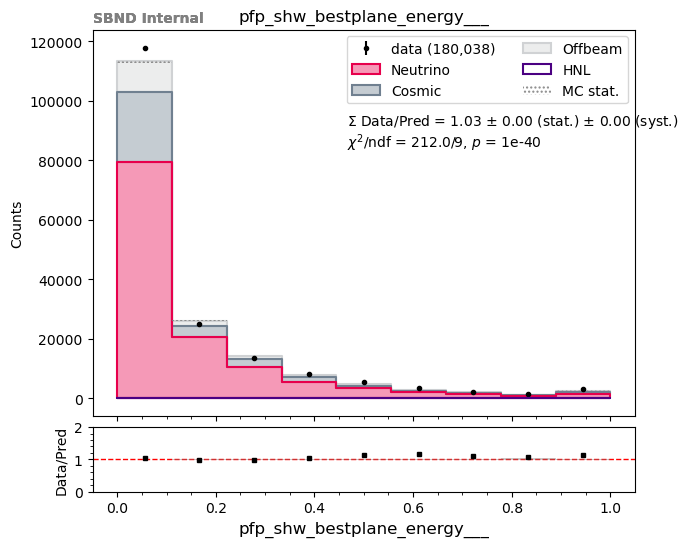

In [3]:
try:
    mc_df, mc_pot, mc_ngen = ana.load_mc(MC_FILE, cuts=ana.DEFAULT_CUTS)

    data_df, data_pot, data_ngates = ana.load_data(
        DATA_FILE, cuts=ana.DEFAULT_CUTS,
        preprocess_fn=getattr(ana, 'preprocess_databnb', ana.preprocess_data),
    )

    offbeam_df, offbeam_pot, offbeam_ngates = ana.load_data(
        OFFBEAM_FILE, onbeam=False,
        offbeam_signal_value=ana.signal_dict["offbeam"],
        cuts=ana.DEFAULT_CUTS,
        preprocess_fn=getattr(ana, 'preprocess_dataoff', ana.preprocess_data),
    )

    hnl_df, hnl_pot, hnl_info = ana.load_mchnl(MCHNL_FILE, cuts=ana.DEFAULT_CUTS)

    f = 0.0725  # TODO: double check for the most-up-to-date fudge factor (see step2a A4)
    ongates_per_pot = data_ngates / data_pot
    scale_offbeam = ((1 - f) * (ongates_per_pot * mc_pot)) / offbeam_ngates

    weight_col = ('weights_mc', '', '', '', '', '')
    mc_df[weight_col] = 1.0
    offbeam_df[weight_col] = scale_offbeam

    mcstat_cols = ['__ntuple', 'entry', 'rec.slc..index', 'run', 'subrun', 'evt', 'sample']
    mc_top_level = set(mc_df.columns.get_level_values(0)) | set(mc_df.index.names)
    if 'file_idx' in mc_top_level:
        mcstat_cols.append('file_idx')  # only from concat_hdf.py (step5) -- fine if absent here

    mc_df = pd.concat([
        ana.mcstat(mc_df.assign(sample=0).set_index("sample", append=True).reset_index(), cols=mcstat_cols),
        offbeam_df.assign(sample=1).set_index("sample", append=True).reset_index(),
    ])

    ana.plot_mc_hnl_data(
        mc_df, hnl_df, data_df, VAR, bins=BINS,
        scale_nu=data_pot / mc_pot,
        scale_hnl=data_pot / hnl_pot,
        categories=ana.background_categories,
        hnl_categories={"hnl": ana.signal_categories["hnl"]},
    )
except Exception as e:
    print("Expected -- neither a real data file nor an \"offbeam\" category exist yet:")
    print(f"  {type(e).__name__}: {e}")